In [ ]:
# 1. Connect Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Libraries used across the notebook
import os
import gc
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 3. Project paths
PROJECT_DIR = '/content/drive/MyDrive/ECG_Vision_App'
DATA_DIR = os.path.join(PROJECT_DIR, 'data')
PTB_DIR = '/content/ptb-xl'
IMG_DIR = '/content/ecg_images'

# 4. Restore the dataset and the ECG images onto the fast Colab disk
!unzip -q -n {DATA_DIR}/ptb-xl-100hz.zip -d /content
!unzip -q -n {DATA_DIR}/ecg_images.zip -d /content

# 5. Load your saved labels
data = pd.read_csv(os.path.join(DATA_DIR, 'af_vs_normal_labels.csv'), index_col='ecg_id')
print(data['split'].value_counts())
print("Images available:", len(os.listdir(IMG_DIR)))

Mounted at /content/drive
split
train    7759
val       992
test      967
Name: count, dtype: int64
Images available: 9718


In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score

val = data[data['split'] == 'val']
y_true = val['label'].values          # the correct answers (0 = Normal, 1 = AF)
y_pred = np.zeros_like(y_true)        # the "model": always predict 0 = Normal

tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
print("True negatives  (normal, called normal):", tn)
print("False positives (normal, called AF):    ", fp)
print("False negatives (AF, called normal):    ", fn)
print("True positives  (AF, called AF):        ", tp)
print()
print(f"Accuracy:    {accuracy_score(y_true, y_pred):.3f}")
print(f"Sensitivity: {tp / (tp + fn):.3f}")
print(f"Specificity: {tn / (tn + fp):.3f}")
print(f"F1 score:    {f1_score(y_true, y_pred, zero_division=0):.3f}")

True negatives  (normal, called normal): 841
False positives (normal, called AF):     0
False negatives (AF, called normal):     151
True positives  (AF, called AF):         0

Accuracy:    0.848
Sensitivity: 0.000
Specificity: 1.000
F1 score:    0.000


In [ ]:
!pip install -q wfdb neurokit2
import wfdb
import neurokit2 as nk

def load_ecg(ecg_id):
    path = os.path.join(PTB_DIR, data.loc[ecg_id, 'filename_lr'])
    signal, meta = wfdb.rdsamp(path)
    return signal, meta

def rr_irregularity(ecg_id):
    sig, meta = load_ecg(ecg_id)
    lead_ii = sig[:, meta['sig_name'].index('II')]          # take lead II
    cleaned = nk.ecg_clean(lead_ii, sampling_rate=meta['fs'])  # remove noise
    _, info = nk.ecg_peaks(cleaned, sampling_rate=meta['fs'])  # find R peaks
    r_peaks = info['ECG_R_Peaks']                           # positions of the R peaks
    rr = np.diff(r_peaks) / meta['fs']                      # gaps between peaks, in seconds
    return rr, rr.std() / rr.mean()                         # gaps, and how uneven they are

for ecg_id in [1, 282]:
    rr, cv = rr_irregularity(ecg_id)
    print(f"ECG {ecg_id} – label {data.loc[ecg_id, 'label']}")
    print(f"   R-R gaps (seconds): {np.round(rr, 2)}")
    print(f"   Irregularity (CV):  {cv:.3f}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 9.5 MB/s eta 0:00:00
ECG 1 – label 0
   R-R gaps (seconds): [0.93 0.92 0.93 0.94 0.96 0.96 0.94 0.91 0.97]
   Irregularity (CV):  0.020
ECG 282 – label 1
   R-R gaps (seconds): [0.73 0.78 1.06 0.62 0.58 0.82 0.77 0.77 0.63 0.59 0.88 0.5 ]
   Irregularity (CV):  0.203


In [ ]:
from tqdm.auto import tqdm

cvs = {}
for ecg_id in tqdm(data.index):
    try:
        _, cv = rr_irregularity(ecg_id)
    except Exception:
        cv = np.nan          # mark as missing if the peaks couldn't be found
    cvs[ecg_id] = cv

data['rr_cv'] = pd.Series(cvs)

print("ECGs where peaks could not be found:", data['rr_cv'].isna().sum())
print()
print("Typical CV for each group (median):")
print(data.groupby('label')['rr_cv'].median())

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score

# 1. Learn the cut-off on the TRAINING set
train = data[data['split'] == 'train'].dropna(subset=['rr_cv'])

best_cut, best_f1 = None, -1
for cut in np.arange(0.02, 0.40, 0.005):
    pred = (train['rr_cv'] > cut).astype(int)
    f1 = f1_score(train['label'], pred)
    if f1 > best_f1:
        best_cut, best_f1 = cut, f1

print(f"Best cut-off (learned on training set): CV > {best_cut:.3f}")
print(f"Training F1 at that cut-off: {best_f1:.3f}")
print()

# 2. Score the rule on the VALIDATION set
val = data[data['split'] == 'val']
y_true = val['label'].values
y_pred = (val['rr_cv'].fillna(0) > best_cut).astype(int).values

tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
print("Validation results for the R-R rule:")
print("True negatives  (normal, called normal):", tn)
print("False positives (normal, called AF):    ", fp)
print("False negatives (AF, called normal):    ", fn)
print("True positives  (AF, called AF):        ", tp)
print()
print(f"Accuracy:    {accuracy_score(y_true, y_pred):.3f}")
print(f"Sensitivity: {tp / (tp + fn):.3f}")
print(f"Specificity: {tn / (tn + fp):.3f}")
print(f"F1 score:    {f1_score(y_true, y_pred):.3f}")

Best cut-off (learned on training set): CV > 0.110
Training F1 at that cut-off: 0.829

Validation results for the R-R rule:
True negatives  (normal, called normal): 788
False positives (normal, called AF):     53
False negatives (AF, called normal):     15
True positives  (AF, called AF):         136

Accuracy:    0.931
Sensitivity: 0.901
Specificity: 0.937
F1 score:    0.800


In [ ]:
import os

PROJECT_DIR = '/content/drive/MyDrive/ECG_Vision_App'
DATA_DIR = os.path.join(PROJECT_DIR, 'data')

os.makedirs(DATA_DIR, exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Contents:", os.listdir(PROJECT_DIR))

Project folder: /content/drive/MyDrive/ECG_Vision_App
Contents: ['data', 'normal_vs_af_lead2.png']


In [ ]:
!rm -f /content/ptb-xl-1.0.3.zip
!pip install -q awscli
!aws s3 sync --no-sign-request --region us-east-1 s3://physionet-open/ptb-xl/1.0.3/ /content/ptb-xl --exclude "records500/*" --only-show-errors
!du -sh /content/ptb-xl
!ls /content/ptb-xl

In [ ]:
!cd /content && zip -qr ptb-xl-100hz.zip ptb-xl

import shutil
ZIP_DRIVE = os.path.join(DATA_DIR, 'ptb-xl-100hz.zip')
shutil.copy('/content/ptb-xl-100hz.zip', ZIP_DRIVE)

print("Saved to Drive:", ZIP_DRIVE)
print("Size: %.2f GB" % (os.path.getsize(ZIP_DRIVE) / 1e9))

Saved to Drive: /content/drive/MyDrive/ECG_Vision_App/data/ptb-xl-100hz.zip
Size: 0.38 GB


In [ ]:
import pandas as pd

DB_PATH = '/content/ptb-xl/ptbxl_database.csv'
df = pd.read_csv(DB_PATH, index_col='ecg_id')

print("Rows, columns:", df.shape)
df.head()

Rows, columns: (21799, 27)


,patient_id,age,sex,height,weight,nurse,site,device,recording_date,report,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
ecg_id,,,,,,,,,,,,,,,,,,,,,
1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,sinusrhythmus periphere niederspannung,...,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr
2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,sinusbradykardie sonst normales ekg,...,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,sinusrhythmus normales ekg,...,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr
4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,sinusrhythmus normales ekg,...,True,", II,III,AVF",NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr
5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,sinusrhythmus normales ekg,...,True,", III,AVR,AVF",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr


In [ ]:
df['sex'].value_counts(normalize=True)

,proportion
sex,
0,0.52085
1,0.47915


In [ ]:
df[['scp_codes', 'report', 'strat_fold']].head(10)

,scp_codes,report,strat_fold
ecg_id,,,
1,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}",sinusrhythmus periphere niederspannung,3
2,"{'NORM': 80.0, 'SBRAD': 0.0}",sinusbradykardie sonst normales ekg,2
3,"{'NORM': 100.0, 'SR': 0.0}",sinusrhythmus normales ekg,5
4,"{'NORM': 100.0, 'SR': 0.0}",sinusrhythmus normales ekg,3
5,"{'NORM': 100.0, 'SR': 0.0}",sinusrhythmus normales ekg,4
6,"{'NORM': 100.0, 'SR': 0.0}",sinusrhythmus normales ekg,4
7,"{'NORM': 100.0, 'SR': 0.0}","sinusrhythmus linkstyp t abnormal, wahrscheinl...",7
8,"{'IMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}",sinusrhythmus linkstyp qrs(t) abnormal infe...,9
9,"{'NORM': 100.0, 'SR': 0.0}",sinusrhythmus normales ekg,10


In [ ]:
import ast

print("Before:", type(df['scp_codes'].iloc[0]))
df['scp_codes'] = df['scp_codes'].apply(ast.literal_eval)
print("After:", type(df['scp_codes'].iloc[0]))

has_afib = df['scp_codes'].apply(lambda codes: 'AFIB' in codes)
has_norm = df['scp_codes'].apply(lambda codes: 'NORM' in codes)

print("AFIB records:", has_afib.sum())
print("NORM records:", has_norm.sum())
print("Both NORM and AFIB:", (has_afib & has_norm).sum())

Before: <class 'str'>
After: <class 'dict'>
AFIB records: 1514
NORM records: 9514
Both NORM and AFIB: 37


In [ ]:
is_sr = df['scp_codes'].apply(lambda codes: 'SR' in codes)

af_df = df[has_afib]
normal_df = df[has_norm & is_sr & ~has_afib]

print("AF group:", len(af_df))
print("Normal group:", len(normal_df))

AF group: 1514
Normal group: 8204


In [ ]:
af_df = af_df.assign(label=1)
normal_df = normal_df.assign(label=0)
data = pd.concat([normal_df, af_df])

def which_split(fold):
    if fold <= 8:
        return 'train'
    elif fold == 9:
        return 'val'
    else:
        return 'test'

data['split'] = data['strat_fold'].apply(which_split)

pd.crosstab(data['split'], data['label'], margins=True)

label,0,1,All
split,,,
test,815,152,967
train,6548,1211,7759
val,841,151,992
All,8204,1514,9718


In [ ]:
LABELS_PATH = os.path.join(DATA_DIR, 'af_vs_normal_labels.csv')

data[['patient_id', 'filename_lr', 'strat_fold', 'split', 'label']].to_csv(LABELS_PATH)

print("Saved:", LABELS_PATH)

Saved: /content/drive/MyDrive/ECG_Vision_App/data/af_vs_normal_labels.csv


In [ ]:
!pip install -q wfdb # a python library made by Physionet for reading ECG files.
import wfdb

PTB_DIR = '/content/ptb-xl'

normal_id = data[(data['label'] == 0) & (data['split'] == 'train')].index[0]
af_id = data[(data['label'] == 1) & (data['split'] == 'train')].index[0]

def load_ecg(ecg_id):
    path = os.path.join(PTB_DIR, data.loc[ecg_id, 'filename_lr'])
    signal, meta = wfdb.rdsamp(path)
    return signal, meta

sig_normal, meta = load_ecg(normal_id)
sig_af, _ = load_ecg(af_id)

print("Normal ECG id:", normal_id, "| AF ECG id:", af_id)
print("Signal shape:", sig_normal.shape)
print("Sampling rate:", meta['fs'], "Hz")
print("Leads:", meta['sig_name'])

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 5.6 MB/s eta 0:00:00
Normal ECG id: 1 | AF ECG id: 282
Signal shape: (1000, 12)
Sampling rate: 100 Hz
Leads: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


In [ ]:
LAYOUT = [['I', 'AVR', 'V1', 'V4'],
          ['II', 'AVL', 'V2', 'V5'],
          ['III', 'AVF', 'V3', 'V6']]

def render_ecg(signal, lead_names, fs=100, save_path=None):
    idx = {name: i for i, name in enumerate(lead_names)}
    seg = int(2.5 * fs)            # samples in 2.5 seconds
    row_h = 30                     # height of each row in mm
    W, H = 250, 4 * row_h          # 10 s x 25 mm/s = 250 mm wide

    fig = plt.figure(figsize=(W / 25.4, H / 25.4), dpi=100)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, W); ax.set_ylim(0, H); ax.axis('off')

    # ECG paper: small boxes every 1 mm, big boxes every 5 mm
    ax.vlines(np.arange(0, W + 1, 1), 0, H, color='red', lw=0.3, alpha=0.25)
    ax.hlines(np.arange(0, H + 1, 1), 0, W, color='red', lw=0.3, alpha=0.25)
    ax.vlines(np.arange(0, W + 1, 5), 0, H, color='red', lw=0.8, alpha=0.5)
    ax.hlines(np.arange(0, H + 1, 5), 0, W, color='red', lw=0.8, alpha=0.5)

    # Rows 1-3: 12 leads, 2.5 s each
    for r, row in enumerate(LAYOUT):
        baseline = H - (r + 0.5) * row_h
        for c, name in enumerate(row):
            s = signal[c * seg:(c + 1) * seg, idx[name]]
            x = c * 62.5 + np.arange(len(s)) / fs * 25
            ax.plot(x, baseline + s * 10, color='black', lw=0.8)
            ax.text(c * 62.5 + 2, baseline + 9, name, fontsize=7)

    # Row 4: lead II rhythm strip, full 10 s
    baseline = 0.5 * row_h
    s = signal[:, idx['II']]
    ax.plot(np.arange(len(s)) / fs * 25, baseline + s * 10, color='black', lw=0.8)
    ax.text(2, baseline + 9, 'II', fontsize=7)

    if save_path:
        fig.savefig(save_path, dpi=100)
        plt.close(fig)
    return fig

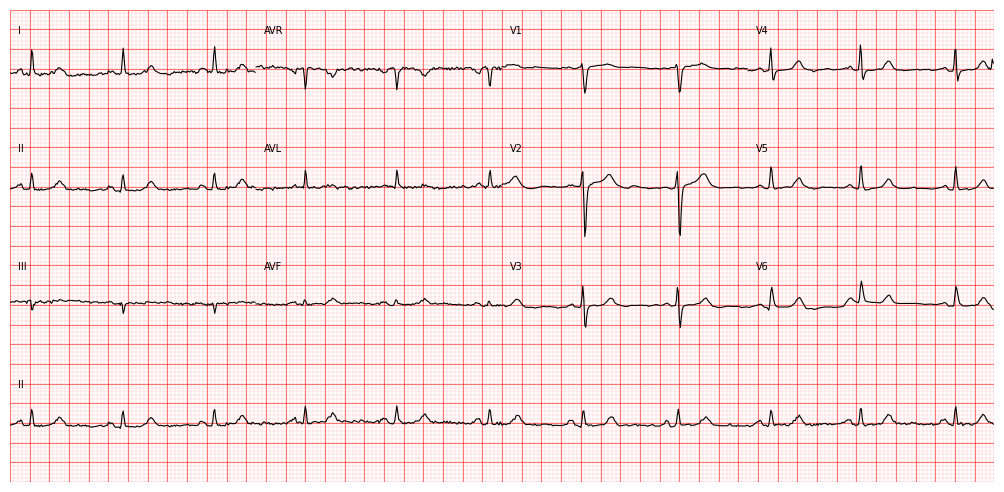

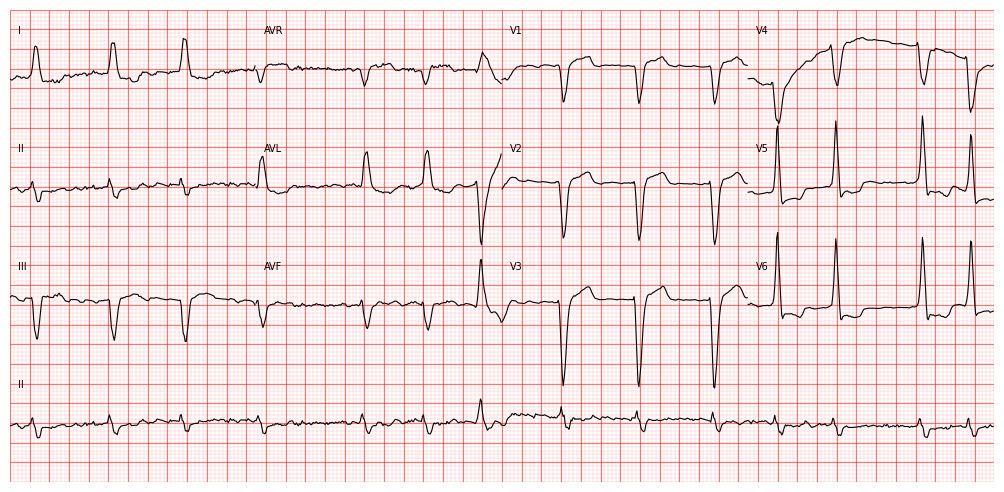

In [ ]:
for ecg_id in [1, 282]:
    sig, meta = load_ecg(ecg_id)
    render_ecg(sig, meta['sig_name'])
    plt.show()

In [ ]:
import time

IMG_DIR = '/content/ecg_images'
os.makedirs(IMG_DIR, exist_ok=True)

start = time.time()
for ecg_id in data.index[:20]:
    sig, meta = load_ecg(ecg_id)
    render_ecg(sig, meta['sig_name'], save_path=f'{IMG_DIR}/{ecg_id}.png')
elapsed = time.time() - start

print(f"20 images took {elapsed:.1f} seconds")
print(f"Estimated time for all {len(data)} images: {elapsed / 20 * len(data) / 60:.0f} minutes")

20 images took 2.7 seconds
Estimated time for all 9718 images: 22 minutes


In [ ]:
import gc
from tqdm.auto import tqdm

plt.switch_backend('agg')   # draw images without displaying them in the notebook

IMG_DIR = '/content/ecg_images'
todo = [i for i in data.index if not os.path.exists(f'{IMG_DIR}/{i}.png')]
print(len(todo), "images left to draw")

for ecg_id in tqdm(todo):
    sig, meta = load_ecg(ecg_id)
    render_ecg(sig, meta['sig_name'], save_path=f'{IMG_DIR}/{ecg_id}.png')
    plt.close('all')   # close every open figure
    gc.collect()       # hand unused memory back to the computer

print("Done:", len(os.listdir(IMG_DIR)), "images in", IMG_DIR)

3018 images left to draw


  0%|          | 0/3018 [00:00<?, ?it/s]

Done: 9718 images in /content/ecg_images


In [ ]:
import shutil

!cd /content && zip -q -r -0 ecg_images.zip ecg_images
!du -sh /content/ecg_images.zip

ZIP_DRIVE = os.path.join(DATA_DIR, 'ecg_images.zip')
shutil.copy('/content/ecg_images.zip', ZIP_DRIVE)
print("Saved to Drive:", ZIP_DRIVE)

994M	/content/ecg_images.zip
Saved to Drive: /content/drive/MyDrive/ECG_Vision_App/data/ecg_images.zip


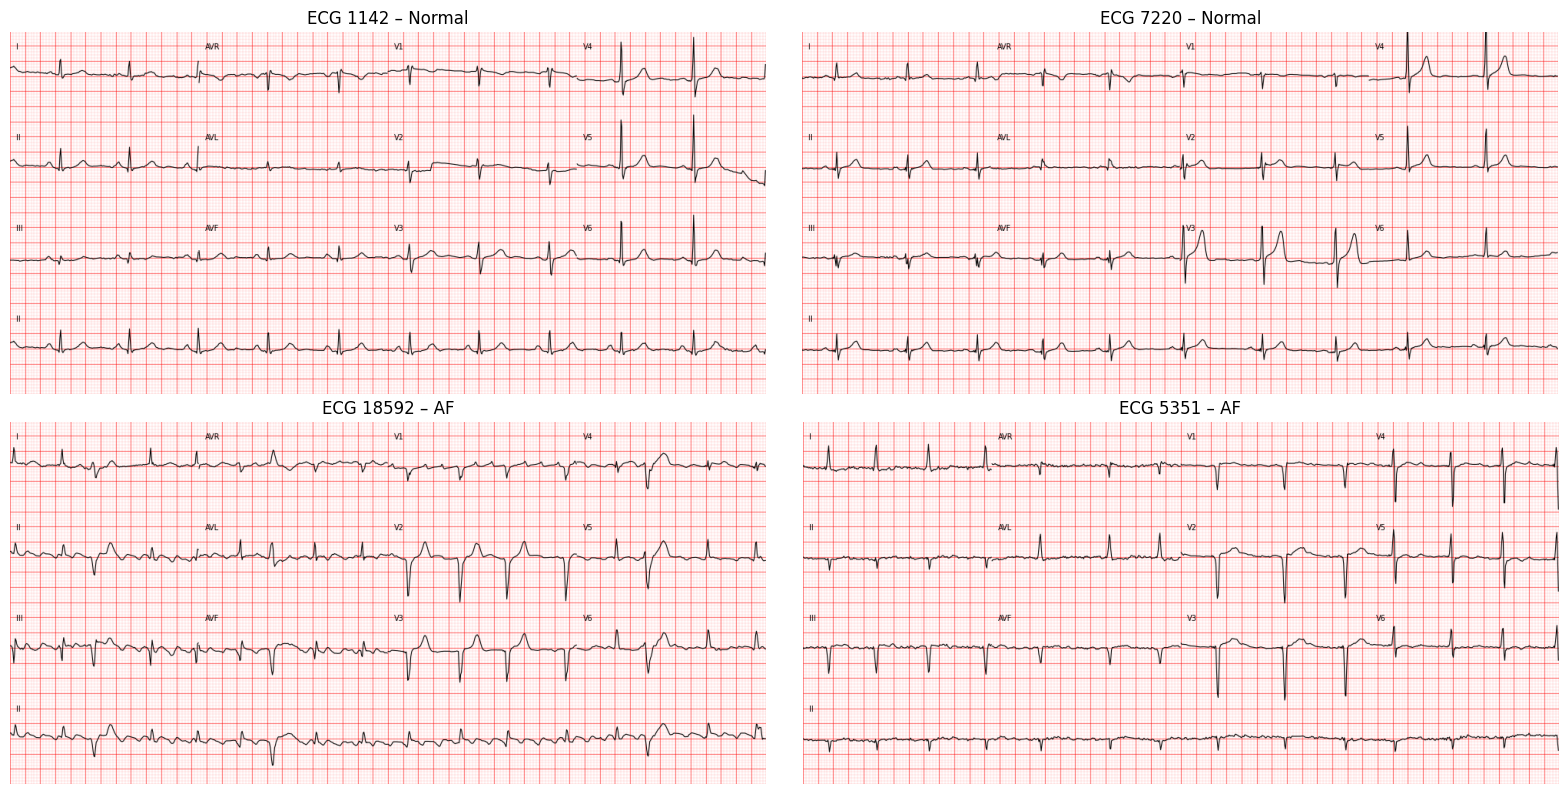

In [ ]:
from PIL import Image

sample = data.groupby('label').sample(2, random_state=0)
fig, axes = plt.subplots(2, 2, figsize=(16, 8))
plt.switch_backend('module://matplotlib_inline.backend_inline')

for ax, (ecg_id, row) in zip(axes.flat, sample.iterrows()):
    ax.imshow(Image.open(f'{IMG_DIR}/{ecg_id}.png'))
    ax.set_title(f"ECG {ecg_id} – {'AF' if row['label'] == 1 else 'Normal'}")
    ax.axis('off')

plt.tight_layout()
plt.show()